# **Import bibliotek, wybór urządzenia i parametry**

In [10]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio

import torch
print("CUDA:", torch.cuda.is_available())


SR = 16000          # częstotliwość próbkowania [Hz] — standard w ASR
N_FFT = 512         # długość okna FFT
HOP_LENGTH = 160    # przesunięcie ramki (10 ms przy 16 kHz)
N_MELS = 64         # liczba pasm mel

CUDA: True


In [6]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

# ***Odsłuch**

Samogłoska: "O"

Wyraz: "Chrząszcz"

Zdanie: "Chrząszcz brzmi w trzcinie"


In [11]:
from IPython.display import display, Audio

pliki = ['samogloska.wav', 'wyraz.wav', 'zdanie.wav']

for sciezka in pliki:
    print(f"Odsłuch pliku: {sciezka}")
    y_audio, sr_audio = librosa.load(sciezka, sr=SR, mono=True)
    display(Audio(y_audio, rate=sr_audio))

Odsłuch pliku: samogloska.wav


Odsłuch pliku: wyraz.wav


Odsłuch pliku: zdanie.wav


# **Wczytanie plików, generowanie reprezentacji i porównanie nagrań**


Analiza pliku: samogloska.wav
Liczba próbek: 29568
Czas trwania: 1.85 s

Kształt log-mel: (64, 185)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 185)  (współczynniki × ramki czasowe)



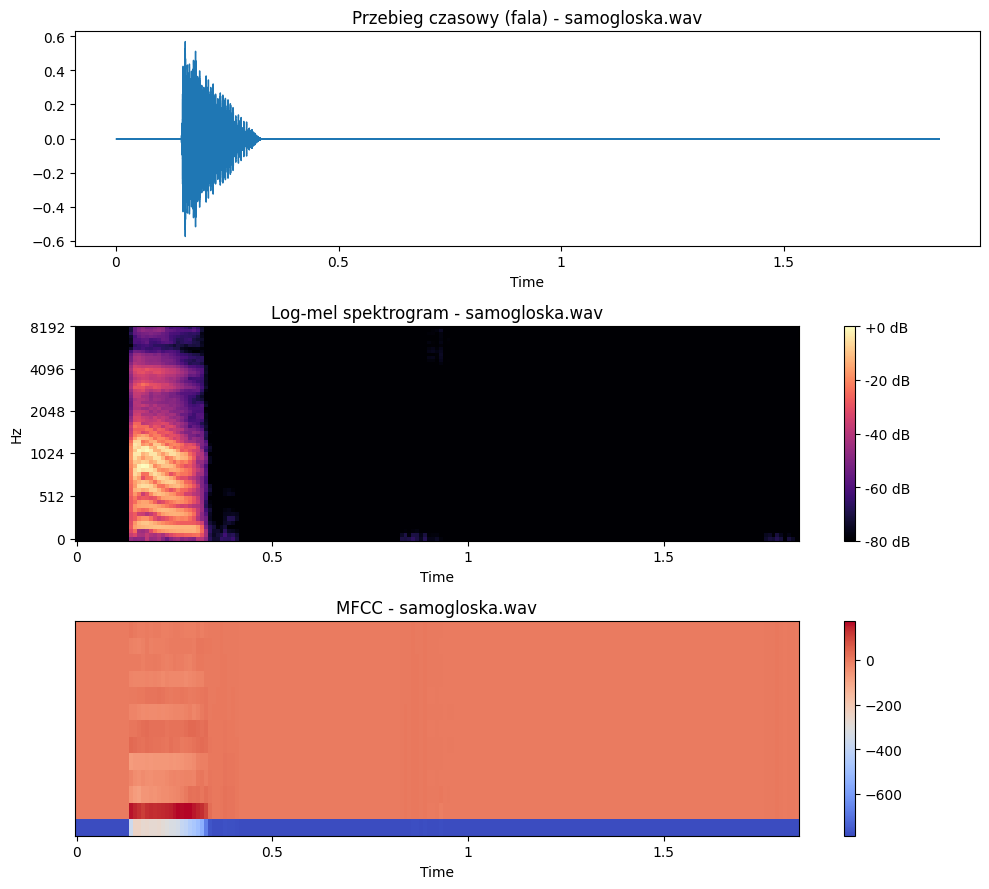

Analiza pliku: wyraz.wav
Liczba próbek: 29568
Czas trwania: 1.85 s

Kształt log-mel: (64, 185)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 185)  (współczynniki × ramki czasowe)



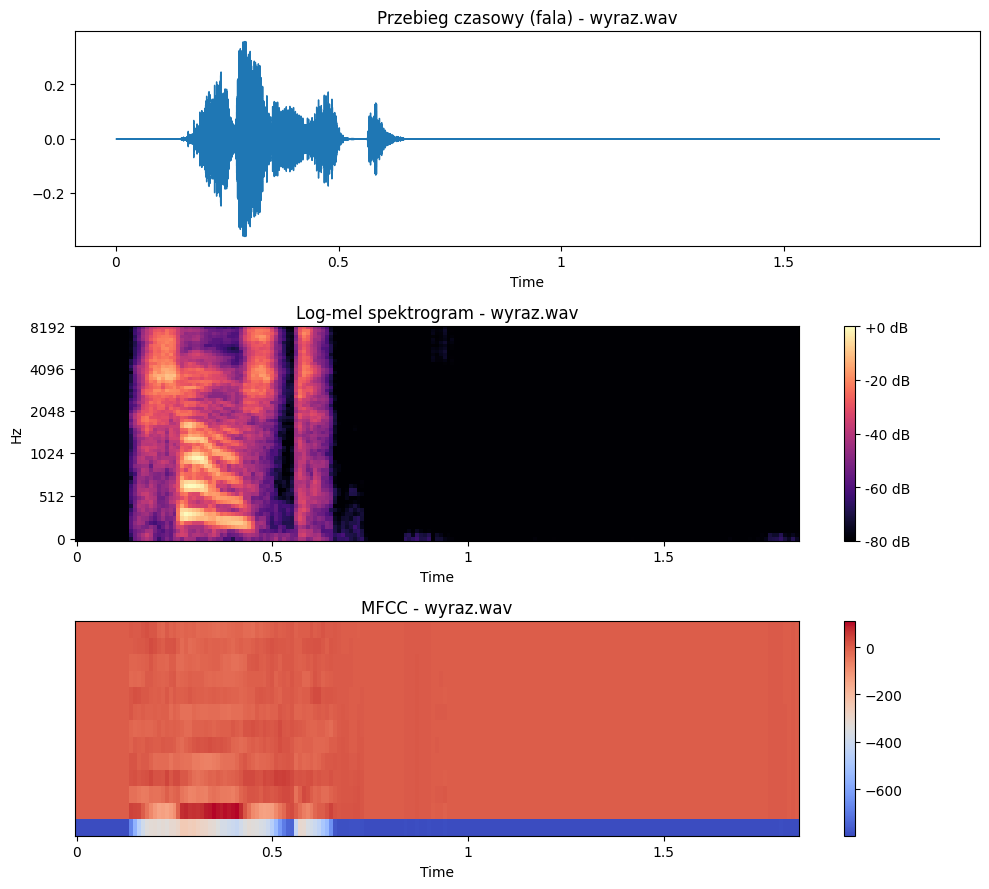

Analiza pliku: zdanie.wav
Liczba próbek: 37632
Czas trwania: 2.35 s

Kształt log-mel: (64, 236)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 236)  (współczynniki × ramki czasowe)



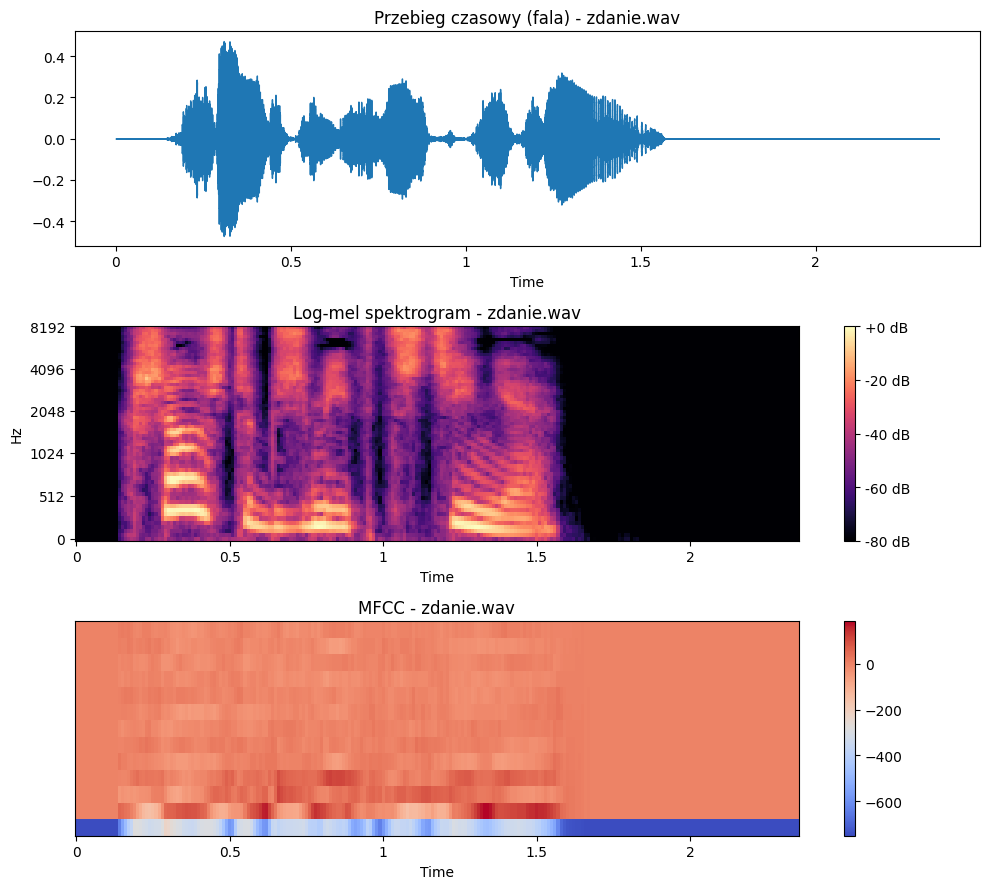

In [12]:
pliki = ['samogloska.wav', 'wyraz.wav', 'zdanie.wav'] #lista plików

for sciezka in pliki:
    print(f"Analiza pliku: {sciezka}")

    y, sr = librosa.load(sciezka, sr=SR, mono=True) #qczytanie audio do 16 kHz mono

    print(f"Liczba próbek: {len(y)}")
    print(f"Czas trwania: {len(y) / sr:.2f} s\n")


    S_db = log_mel(y, sr) #generowanie reprezentacji
    M = mfcc(y, sr)

    print(f"Kształt log-mel: {S_db.shape}  (pasma mel × ramki czasowe)")
    print(f"Kształt MFCC:    {M.shape}  (współczynniki × ramki czasowe)\n")

    fig, ax = plt.subplots(3, 1, figsize=(10, 9)) #wizualizacja

    librosa.display.waveshow(y, sr=sr, ax=ax[0])
    ax[0].set_title(f"Przebieg czasowy (fala) - {sciezka}")

    img1 = librosa.display.specshow(
        S_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
    )
    ax[1].set_title(f"Log-mel spektrogram - {sciezka}")
    fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

    img2 = librosa.display.specshow(
        M, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
    )
    ax[2].set_title(f"MFCC - {sciezka}")
    fig.colorbar(img2, ax=ax[2])

    plt.tight_layout()
    plt.show()

# **Badanie wpływu parametrów N_FFT i HOP_LENGTH**

Na przykładzie nagrania "wyraz.wav"

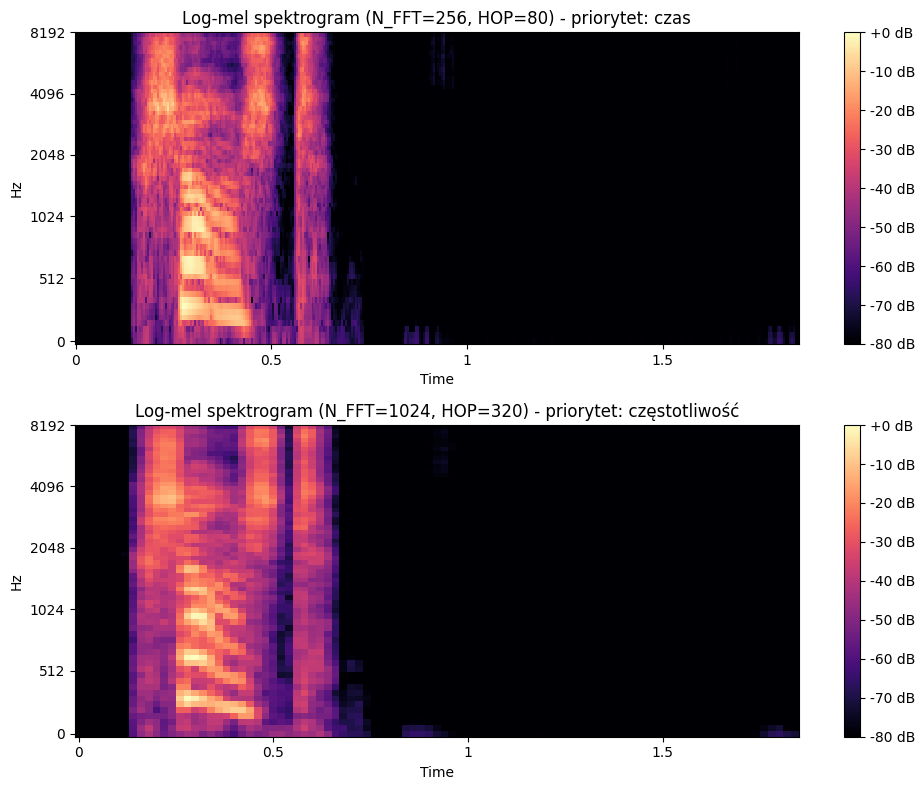

In [9]:
y_test, sr_test = librosa.load('wyraz.wav', sr=SR, mono=True)

#Wariant 1: Krótkie okno (wyższa rozdzielczość czasowa, niższa częstotliwościowa)
n_fft_1 = 256
hop_length_1 = 80
S_db_1 = log_mel(y_test, sr_test, n_fft=n_fft_1, hop_length=hop_length_1)

#Wariant 2: Długie okno (wyższa rozdzielczość częstotliwościowa, niższa czasowa)
n_fft_2 = 1024
hop_length_2 = 320
S_db_2 = log_mel(y_test, sr_test, n_fft=n_fft_2, hop_length=hop_length_2)

fig, ax = plt.subplots(2, 1, figsize=(10, 8)) #wizualizacja porównawcza

img1 = librosa.display.specshow(
    S_db_1, sr=sr_test, hop_length=hop_length_1, x_axis="time", y_axis="mel", ax=ax[0]
)
ax[0].set_title(f"Log-mel spektrogram (N_FFT={n_fft_1}, HOP={hop_length_1}) - priorytet: czas")
fig.colorbar(img1, ax=ax[0], format="%+2.0f dB")

img2 = librosa.display.specshow(
    S_db_2, sr=sr_test, hop_length=hop_length_2, x_axis="time", y_axis="mel", ax=ax[1]
)
ax[1].set_title(f"Log-mel spektrogram (N_FFT={n_fft_2}, HOP={hop_length_2}) - priorytet: częstotliwość")
fig.colorbar(img2, ax=ax[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()